# Estudo 05 – H4: o que acontece depois de um movimento grande?

Hipótese H4 das [notas](../NOTAS.md). Duas ideias clássicas e opostas:

- **Sobrerreação (*overreaction*):** depois de um movimento muito grande, o preço exagerou e tende a **voltar** (reversão);
- **Sub-reação (*underreaction*):** a notícia é absorvida aos poucos, e o movimento tende a **continuar**.

"Grande" é medido em relação à volatilidade recente, para que 100 pts num dia calmo e num dia agitado não sejam tratados igual:

$$z_t = \frac{r_t}{\text{desvio-padrão dos retornos anteriores (só o passado)}}$$

|z| > 2 é um movimento de "2 desvios"; |z| > 3, de "3 desvios".

Perguntas:

1. Movimentos grandes são mais frequentes do que numa distribuição normal?
2. Depois deles há continuação ou reversão? Em que tamanho de candle?
3. Altas e baixas se comportam diferente?
4. Quando "não significativo" quer dizer "não existe", e quando quer dizer "não dá para saber"? (**intervalo de confiança contra o custo**, conceito novo)
5. Se a direção não é previsível, o que é?

**Dados:** WIN, só até 31/12/2024.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
from pathlib import Path
from scipy import stats

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA)); sys.path.append(str(PASTA / "frentes" / "estatistico"))
import tt1_comum as t
import custos as cu

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})
CUSTOS = {nome: p["custo_pts"] for nome, p in cu.CENARIOS.items()}

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]

def holm(pvals, alfa=0.05):
    p = np.asarray(pvals); ordem = np.argsort(p); m = len(p); ok = np.zeros(m, bool)
    for i, j in enumerate(ordem):
        if p[j] <= alfa / (m - i):
            ok[j] = True
        else:
            break
    return ok

JANELA_VOL = {1: 60, 5: 48, 15: 32, 60: 20}         # nº de candles para a volatilidade recente (~1 pregão; 1 h no de 1 min)
bases = {}
for k in [1, 5, 15, 60]:
    c = win if k == 1 else win.resample(f"{k}min").agg({"open": "first", "high": "max", "low": "min", "close": "last"}).dropna()
    d = pd.Series(c.index.normalize(), index=c.index)
    r = np.log(c.close).diff(); r[d != d.shift()] = np.nan                  # dentro do pregão
    vol = r.rolling(JANELA_VOL[k], min_periods=JANELA_VOL[k] // 2).std().shift(1)   # só o passado
    bases[k] = pd.DataFrame({"close": c.close, "dia": d, "r": r, "z": r / vol})
print({k: len(v) for k, v in bases.items()})

{1: 513736, 5: 102788, 15: 34581, 60: 8914}


## 1. Movimentos grandes são mais frequentes que numa normal?

In [2]:
linhas = []
for k, b in bases.items():
    z = b.z.dropna()
    linhas.append(dict(candle_min=k, frac_z_maior_2=np.mean(z.abs() > 2), normal_2=2 * (1 - stats.norm.cdf(2)),
                       frac_z_maior_3=np.mean(z.abs() > 3), normal_3=2 * (1 - stats.norm.cdf(3))))
tab1 = pd.DataFrame(linhas)
tab1["vezes_mais_que_normal_3"] = tab1.frac_z_maior_3 / tab1.normal_3
tab1.round(4)

,candle_min,frac_z_maior_2,normal_2,frac_z_maior_3,normal_3,vezes_mais_que_normal_3
0,1,0.0582,0.0455,0.0145,0.0027,5.3670
1,5,0.0649,0.0455,0.0185,0.0027,6.8383
2,15,0.0703,0.0455,0.0207,0.0027,7.6765
3,60,0.0745,0.0455,0.0210,0.0027,7.7612


**Leitura:** movimentos de mais de 2 desvios acontecem 1,3 a 1,6 vez mais que numa normal, e os de mais de 3 desvios, **5 a 8 vezes mais** (mais nos candles maiores). São as **caudas gordas** (Estudo 01, Seção 6). Movimentos grandes não são raridades; acontecem várias vezes por semana.

## 2. Continuação ou reversão?

Para cada tamanho de candle (1, 5, 15 e 60 min), limiar (|z| > 2 ou > 3) e horizonte (o candle seguinte, ou os 3 seguintes): o resultado de entrar no fechamento do candle grande **a favor** do movimento. Positivo é continuação; negativo, reversão. São 16 testes.

In [3]:
linhas = []
for k, b in bases.items():
    cl, dd, z = b.close.values, b.dia.values, b.z.values
    for H in [1, 3]:
        fut = np.full(len(b), np.nan); fut[:-H] = cl[H:] - cl[:-H]
        mesmo_dia = np.r_[dd[H:] == dd[:-H], np.zeros(H, bool)]; fut[~mesmo_dia] = np.nan
        for lim in [2, 3]:
            s = (np.abs(z) > lim) & ~np.isnan(fut)
            cont = np.sign(z[s]) * fut[s]
            ep = cont.std() / np.sqrt(s.sum())
            linhas.append(dict(candle_min=k, candles_depois=H, z_minimo=lim, n=s.sum(), continuacao_pts=cont.mean(),
                               erro_padrao=ep, t=cont.mean() / ep))
tab2 = pd.DataFrame(linhas)
tab2["p"] = 2 * (1 - stats.norm.cdf(tab2.t.abs()))
tab2["signif_holm"] = holm(tab2.p)
tab2.round(3)

,candle_min,candles_depois,z_minimo,n,continuacao_pts,erro_padrao,t,p,signif_holm
0,1,1,2,29387,-0.246,0.434,-0.568,0.570,False
1,1,1,3,7160,0.117,1.182,0.099,0.921,False
2,1,3,2,29291,0.138,0.703,0.197,0.844,False
3,1,3,3,7141,1.589,1.824,0.871,0.384,False
4,5,1,2,6473,1.566,1.992,0.786,0.432,False
5,5,1,3,1826,2.982,4.365,0.683,0.495,False
6,5,3,2,6403,-0.955,3.251,-0.294,0.769,False
7,5,3,3,1814,-7.641,6.890,-1.109,0.267,False
8,15,1,2,2340,-2.682,5.501,-0.487,0.626,False
9,15,1,3,693,-4.026,11.444,-0.352,0.725,False


**Leitura:** nenhum dos 16 testes passa de |t| = 1,2, e nenhum é significativo, nem antes da correção. **Nem continuação nem reversão** depois de movimentos grandes, em nenhum tamanho de candle. Os sinais variam ao acaso (levemente negativos em 15 e 60 min, mas com erros enormes).

### 2.1 Altas e baixas separadas

Uma ideia comum é que quedas fortes (pânico) exageram mais que altas e revertem mais.

In [4]:
linhas = []
for k in [5, 15, 60]:
    b = bases[k]
    fut = b.close.shift(-1) - b.close; fut[b.dia.shift(-1) != b.dia] = np.nan
    for lado, m in [("alta (z > 2)", b.z > 2), ("baixa (z < −2)", b.z < -2)]:
        s = m & fut.notna(); cont = np.sign(b.z[s]) * fut[s]
        linhas.append(dict(candle_min=k, lado=lado, n=s.sum(), continuacao_pts=cont.mean(), erro_padrao=cont.std() / np.sqrt(s.sum())))
pd.DataFrame(linhas).round(2)

,candle_min,lado,n,continuacao_pts,erro_padrao
0,5,alta (z > 2),3163,-1.27,2.94
1,5,baixa (z < −2),3310,4.27,2.70
2,15,alta (z > 2),1174,-0.01,7.87
3,15,baixa (z < −2),1166,-5.37,7.69
4,60,alta (z > 2),284,-25.74,25.01
5,60,baixa (z < −2),299,-8.19,25.45


**Leitura:** altas e baixas se comportam igual (todas as diferenças estão dentro do erro). Não há assimetria.

## 3. "Não existe" ou "não dá para saber"? O intervalo de confiança contra o custo

No Estudo 03 vimos que, com poucas observações, "não significativo" quer dizer "não dá para saber". Mas nem sempre é assim. O **intervalo de confiança de 95%** (≈ estimativa ± 2 erros-padrão) dá a faixa de valores compatíveis com os dados. Comparando o **topo** desse intervalo com o custo:

| Situação | Conclusão |
|---|---|
| Intervalo inteiro **abaixo** do custo | **Não paga.** Mesmo no melhor caso compatível com os dados, a estratégia não cobre o custo. É **evidência de ausência** |
| Intervalo inteiro **acima** do custo | Paga (com 95% de confiança) |
| Intervalo **contém** o custo | **Não dá para saber** |

Aplicando ao horizonte de 1 candle depois de |z| > 2. O sinal pode ser explorado nos dois sentidos (seguir ou ir contra o movimento), então usamos o **valor absoluto** da estimativa: o melhor caso é |estimativa| + 2 erros-padrão.

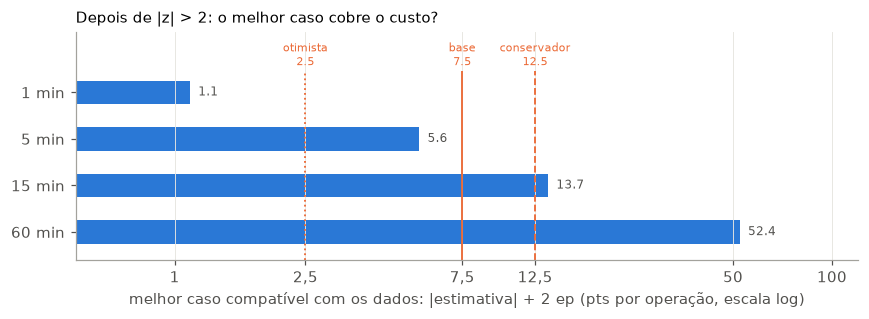

,candle_min,n,continuacao_pts,erro_padrao,melhor_caso_pts,conclusao
0,1,29387,-0.25,0.43,1.11,"não paga nem no otimista (2,5)"
4,5,6473,1.57,1.99,5.55,"não paga no base (7,5)"
8,15,2340,-2.68,5.50,13.68,não dá para saber
12,60,583,-16.74,17.83,52.40,não dá para saber


In [5]:
sub = tab2[(tab2.candles_depois == 1) & (tab2.z_minimo == 2)].copy()
sub["melhor_caso_pts"] = sub.continuacao_pts.abs() + 2 * sub.erro_padrao
def classifica(m):
    if m < CUSTOS["otimista"]:
        return "não paga nem no otimista (2,5)"
    if m < CUSTOS["base"]:
        return "não paga no base (7,5)"
    if m < CUSTOS["conservador"]:
        return "não paga no conservador (12,5)"
    return "não dá para saber"
sub["conclusao"] = sub.melhor_caso_pts.apply(classifica)

fig, ax = plt.subplots(figsize=(8, 3.0))
ys = np.arange(len(sub))[::-1]
ax.barh(ys, sub.melhor_caso_pts, color=AZUL, height=0.5)
for y, v in zip(ys, sub.melhor_caso_pts):
    ax.text(v * 1.06, y, f"{v:.1f}", va="center", fontsize=8, color="#52514e")
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    ax.vlines(CUSTOS[nome], -0.6, len(sub) - 0.55, color=LARANJA, lw=1.2, ls=estilo)
    ax.text(CUSTOS[nome], len(sub) - 0.5, f"{nome}\n{CUSTOS[nome]:g}", color=LARANJA, fontsize=7.5, ha="center", va="bottom")
ax.set_xscale("log"); ax.set_xlim(0.5, 120)
ax.set_xticks([1, 2.5, 7.5, 12.5, 50, 100], ["1", "2,5", "7,5", "12,5", "50", "100"]); ax.minorticks_off()
ax.set_yticks(ys, [f"{k} min" for k in sub.candle_min]); ax.set_ylim(-0.6, len(sub) + 0.3); ax.grid(axis="y", visible=False)
ax.set_xlabel("melhor caso compatível com os dados: |estimativa| + 2 ep (pts por operação, escala log)")
ax.set_title("Depois de |z| > 2: o melhor caso cobre o custo?", loc="left", fontsize=10)
fig.tight_layout(); plt.show()
sub[["candle_min", "n", "continuacao_pts", "erro_padrao", "melhor_caso_pts", "conclusao"]].round(2)

**Leitura:**

- **1 min:** o melhor caso é ≈ 1,1 pt. **Não paga nem no cenário otimista.** Com ~29 mil movimentos grandes, temos poder de sobra: se houvesse algo explorável, veríamos.
- **5 min:** melhor caso ≈ 5,5 pts. **Não paga no cenário base.**
- **15 e 60 min:** o intervalo contém todos os custos. **Não dá para saber.** Há poucos eventos e muito ruído por evento.

É a mesma troca do Estudo 03, vista do outro lado: onde há muitos dados, conseguimos **descartar** o efeito; onde há poucos, só conseguimos dizer "inconclusivo".

## 4. O que é previsível depois de um movimento grande: o tamanho

A direção não é previsível. E o **tamanho** do próximo movimento? Comparamos o |próximo movimento| depois de um candle grande (|z| > 2) com o que vem depois de um candle comum (|z| < 1).

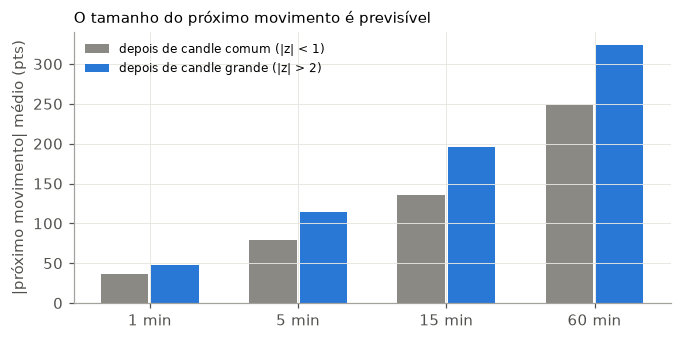

,candle_min,prox_mov_apos_grande_pts,prox_mov_apos_comum_pts,razao
0,1,48.27,35.95,1.34
1,5,114.85,78.59,1.46
2,15,195.89,135.10,1.45
3,60,324.00,248.16,1.31


In [6]:
linhas = []
for k, b in bases.items():
    fut = b.close.shift(-1) - b.close; fut[b.dia.shift(-1) != b.dia] = np.nan
    grande, comum = (b.z.abs() > 2) & fut.notna(), (b.z.abs() < 1) & fut.notna()
    linhas.append(dict(candle_min=k, prox_mov_apos_grande_pts=fut[grande].abs().mean(),
                       prox_mov_apos_comum_pts=fut[comum].abs().mean()))
tab4 = pd.DataFrame(linhas)
tab4["razao"] = tab4.prox_mov_apos_grande_pts / tab4.prox_mov_apos_comum_pts

fig, ax = plt.subplots(figsize=(7, 3.2))
xs = np.arange(len(tab4))
ax.bar(xs - 0.17, tab4.prox_mov_apos_comum_pts, width=0.32, color=CINZA, label="depois de candle comum (|z| < 1)")
ax.bar(xs + 0.17, tab4.prox_mov_apos_grande_pts, width=0.32, color=AZUL, label="depois de candle grande (|z| > 2)")
ax.set_xticks(xs, [f"{k} min" for k in tab4.candle_min]); ax.set_ylabel("|próximo movimento| médio (pts)")
ax.legend(frameon=False, fontsize=8); ax.set_title("O tamanho do próximo movimento é previsível", loc="left", fontsize=10)
plt.show()
tab4.round(2)

**Leitura:** depois de um candle grande, o próximo movimento é **30–50% maior** que o normal, mas em direção imprevisível. É o **agrupamento de volatilidade** de novo: a direção é ruído, o tamanho tem memória.

Consequência prática: depois de um movimento grande, o risco de qualquer operação aumenta. Stops e alvos fixos em pontos ficam "apertados demais"; stops e alvos proporcionais à volatilidade, como os do simulador comum, se ajustam. Isso é o tema da H6 (previsibilidade da volatilidade).

## 5. Conclusões de H4

| Pergunta | Resposta |
|---|---|
| Movimentos grandes são frequentes? | Sim: os de mais de 3 desvios são 5 a 8 vezes mais frequentes que numa normal (caudas gordas) |
| Continuação ou reversão depois deles? | **Nenhuma**, em nenhum candle (1, 5, 15, 60 min), limiar ou horizonte: 16 testes, nenhum |t| > 1,2 |
| Altas × baixas? | Iguais |
| Dá para afirmar que não paga? | **Em 1 min, sim** (não paga nem no otimista); **em 5 min, no cenário base**. Em 15 e 60 min, **não dá para saber** |
| O que é previsível? | O **tamanho** do próximo movimento: 30–50% maior depois de um candle grande. Leva à H6 |

**Lição geral:** comparar o **intervalo de confiança** com o custo, e não só o p-valor com 0,05. Assim se distingue "não existe nada que pague" (intervalo inteiro abaixo do custo) de "não dá para saber" (intervalo contém o custo). As duas coisas aparecem como "não significativo", mas querem dizer coisas opostas para a decisão.

Não há candidato novo nesta hipótese.